# STAT 301: Assignment 2

#### Name: Sean Liu

#### Group Number: G11

#### Group Members: 
- Sean Liu
- Carlo Magaoay
- Samantha Cham
- Prabhnoor Karwal


In [1]:
library(tidyverse)
library(rsample)
library(broom)
library(pROC)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Type 'citation("pROC")' for a citation.


Attaching package: ‘pROC’


The following objects are masked from ‘package:stats’:

    cov, smooth, var




## Section 1: Data Description (15pts)

#### a) Provide a brief description of the dataset assigned to your group. If only part of the data will be used, a clear and reasonable justification is included. Indicate how the data were collected or explain what you will assume about the data collection process. (Reasoning: 5pts)

The dataset assigned to my group contains data from 2012 to 2014 about 2240 customers across 29 different variables from a company's marketing database. 

The dataset's variables cover helpful demographics such as birth year and education as well as company specific data such as purchase counts per channel and number of web visits. 

The Kaggle description does not provide data collection methodology, I will assume that this data represents a company's full customer records from the period it was collected. 

In other words, this data was observed and customers were not randomly assigned to campaigns. Thus, I can establish association, not causation when I build my logistic regression model.

#### b) Write reproducible code to obtain the number of observations and variables. A table with the names and types of the variables. (Code: 5pts)

First, I obtain the number of observations and variables in our full dataset. 

Making sure the code is reproducible across all machines, I downloaded the dataset off Kaggle and uploaded it to my public GitHub Repository I created for the assignment. 

I then read the CSV into this Jupyter Notebook, using read.delim as the downloaded CSV is tab-separated, not comma-separated. I call this original, unaltered dataset as "customers".

`dim(customers)` then gives us the number of observations and variables.

In [2]:
customers <- read.delim("https://raw.githubusercontent.com/Shobby9451/STAT-301/refs/heads/main/marketing_campaign.csv")
dim(customers)


[1] 2240   29

I can see that the dataset has a total of 2240 observations of customers. For each customer, I collect 29 different variables of data. 

Now, I create a table with the names and types of variables so I can see what characteristics and information about our customers I am working with.

I create a tibble with the first column being the variable names of dataframe "customers". I obtain this by using names, which takes the dataset "customers" and returns a character vector of the column names. 

The second column of the tibble contains the types of the variables. I do this by mapping each column of "customers" and creating a character vector with the type of each column. The 1 indexing makes sure that each variable only contains the first class type in case of multiple class types.



In [3]:
tibble(variable = names(customers),
       type = purrr::map_chr(customers, ~ class(.x)[1]))

variable,type
<chr>,<chr>
ID,integer
Year_Birth,integer
Education,character
Marital_Status,character
Income,integer
Kidhome,integer
Teenhome,integer
Dt_Customer,character
Recency,integer


#### c) Include the data source and the citation requested by the owner(s). (Correctness: 5pts)

Just as important is the data analysis itself is making sure I attribute the data source to its owner and include the appropriate citations.

Looking at the Kaggle page, I can see that the dataset was provided by Dr. Omar Romero-Hernandez. Thus, I can create the following citation:

Data source: Patel, A. "Customer Personality Analysis." Kaggle. https://www.kaggle.com/datasets/imakash3011/customer-personality-analysis (accessed Oct 2026). Dataset provided by Dr. Omar Romero-Hernandez, as acknowledged on the source page.

## Section 2: Question (20pts)

#### a) Clearly state the question you want to answer using the provided dataset and concepts learned in the course for Logistic regression. The datasets are rich, so think of a broader question rather than focusing only on the relationship between two variables. Briefly justify why the question is meaningful and explain why it can be addressed with the available data. Explain whether your question focuses on prediction, inference, or both. (Reasoning: 10pts)

Question: What is the probability that a given customer will accept the offer in the next campaign and what are the factors that contribute the most to final accept/reject decision? 

Rationale: This question is meaningful because every company's marketing department has the same goal: to have their marketing campaigns translate into sales and revenue. Understanding which customer leads are likely to convert to sales can help optimize the marketing department's campaign targeting effort. The dataset's variables contain historical information on customer demographics and behaviour which helps us extrapolate our data into future campaigns. This question focuses on both prediction and inference; predicting which customers will accept future campaign efforts and understanding the factors that lead to that decision.

#### b) Indicate which variable you will use as the binary response variable to answer the question. Which covariates do you anticipate will be the most important in the analysis? (Reasoning: 5pts)

My binary response variable will be `Response`, with 1 representing an acceptance of an offer of the last marketing campaign and 0 representing a rejection.

The covariates that I anticipate to be the most important in the analysis are past campaign responses `AcceptedCmp1` - `AcceptedCmp5` , as well as `Income`, `Recency`, and the total spending of customers which can be found by summing the `Mnt` columns.

Past accepted campaigns logically makes sense to help us predict the likelihood of the acceptance of our next campaign. A higher income means that a customer has the means to accept an offer from a campaign. Recency counts the days since the customer made their last purchase and recent buyers may be inclined to buy again. Lastly, the total spending of a customer tells us if they are actually making buying decisions at our company opposed to just income.

#### c) Explain the role that other variables in the dataset may play (e.g., controlling for demographic characteristics). (Reasoning: 5pts)

Other variables in the dataset, especially variables that describe customer demographics such as `Education` and `Marital_Status` will be used to reduce confounding. The relationship between variables such as the acceptance/rejection of past campaigns and the binary response variable `Response` can be misleading.

For example, my model can find that past acceptors of campaigns is associated with high acceptance rates for the new campaign. However, without the control variable of `Income`, it could be that income was the actual reason behind the higher acceptance rates if past acceptors also happened to have higher incomes on average.

By including these control variables in the model and holding them constant, I can isolate for the association between our target covariates and the response variable.

## Section 3: Exploratory Data Analysis and Visualization (45 pts)

#### a) Load the dataset into your Jupyter notebook. The code should be fully reproducible, so it cannot read the dataset from a local folder on your computer. (Mechanics: 5pts)

The dataset has already been loaded in Section 1. Thus, we can call the dataset again by calling the "customers" variable that the dataset is stored in

In [4]:
customers

ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,⋯,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
<int>,<int>,<chr>,<chr>,<int>,<int>,<int>,<chr>,<int>,<int>,⋯,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
5524,1957,Graduation,Single,58138,0,0,04-09-2012,58,635,⋯,7,0,0,0,0,0,0,3,11,1
2174,1954,Graduation,Single,46344,1,1,08-03-2014,38,11,⋯,5,0,0,0,0,0,0,3,11,0
4141,1965,Graduation,Together,71613,0,0,21-08-2013,26,426,⋯,4,0,0,0,0,0,0,3,11,0
6182,1984,Graduation,Together,26646,1,0,10-02-2014,26,11,⋯,6,0,0,0,0,0,0,3,11,0
5324,1981,PhD,Married,58293,1,0,19-01-2014,94,173,⋯,5,0,0,0,0,0,0,3,11,0
7446,1967,Master,Together,62513,0,1,09-09-2013,16,520,⋯,6,0,0,0,0,0,0,3,11,0
965,1971,Graduation,Divorced,55635,0,1,13-11-2012,34,235,⋯,6,0,0,0,0,0,0,3,11,0
6177,1985,PhD,Married,33454,1,0,08-05-2013,32,76,⋯,8,0,0,0,0,0,0,3,11,0
4855,1974,PhD,Together,30351,1,0,06-06-2013,19,14,⋯,9,0,0,0,0,0,0,3,11,1


#### b) Clean and wrangle your data into a tidy format. (Code: 5pts)

Cleaning and wrangling data into a tidy format typically means to transform the dataset to follow three main guidelines. 

1. Columns should represent variables. This means that each covariate should have its own dedicated column and not combined into one column.

2. Rows should represent observations. This means that each row should represent exactly one observation. In the case of our customer dataset, each row should record one customer's information

3. Each cell should represent a single value. Each intersection of a row and column should contain exactly a single piece of data. There should not be any combinations of different variables or pairs of data.

Let's use glimpse(customers) to visually inspect our data to determine if our data is tidy or not

In [5]:
glimpse(customers)

Rows: 2,240
Columns: 29
$ ID                  <int> 5524, 2174, 4141, 6182, 5324, 7446, 965, 6177, 485…
$ Year_Birth          <int> 1957, 1954, 1965, 1984, 1981, 1967, 1971, 1985, 19…
$ Education           <chr> "Graduation", "Graduation", "Graduation", "Graduat…
$ Marital_Status      <chr> "Single", "Single", "Together", "Together", "Marri…
$ Income              <int> 58138, 46344, 71613, 26646, 58293, 62513, 55635, 3…
$ Kidhome             <int> 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1,…
$ Teenhome            <int> 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1,…
$ Dt_Customer         <chr> "04-09-2012", "08-03-2014", "21-08-2013", "10-02-2…
$ Recency             <int> 58, 38, 26, 26, 94, 16, 34, 32, 19, 68, 11, 59, 82…
$ MntWines            <int> 635, 11, 426, 11, 173, 520, 235, 76, 14, 28, 5, 6,…
$ MntFruits           <int> 88, 1, 49, 4, 43, 42, 65, 10, 0, 0, 5, 16, 61, 2, …
$ MntMeatProducts     <int> 546, 6, 127, 20, 118, 98, 164, 56, 24, 6, 6, 11, 4…
$ MntFishProduct

I can see that our dataset fulfills our "tidy" requirements. Each variable has its own column and each observation has its own row. Within each cell, there is a single value representing a piece of information about the observation.

#### c) How many missing values are there for each variable in the dataset? Are there any variables with a large proportion of missing data (e.g., more than 20%)? (Code: 5pts, Reasoning: 5pts)

I can use `colSums(is.na(customers))` to list out all the variables in our dataset as well as the number of missing values there are for each variable. I do this now.

In [6]:
colSums(is.na(customers))

ID          Year_Birth           Education      Marital_Status 
                  0                   0                   0                   0 
             Income             Kidhome            Teenhome         Dt_Customer 
                 24                   0                   0                   0 
            Recency            MntWines           MntFruits     MntMeatProducts 
                  0                   0                   0                   0 
    MntFishProducts    MntSweetProducts        MntGoldProds   NumDealsPurchases 
                  0                   0                   0                   0 
    NumWebPurchases NumCatalogPurchases   NumStorePurchases   NumWebVisitsMonth 
                  0                   0                   0                   0 
       AcceptedCmp3        AcceptedCmp4        AcceptedCmp5        AcceptedCmp1 
                  0                   0                   0                   0 
       AcceptedCmp2            Complain       Z_CostContact           Z_Revenue 
                  0                   0                   0                   0 
           Response 
                  0

I can see that our dataset has limited missing values across our variables. In fact, only our `Income` variable has missing values, 24 respectively.

With a total of 2240 observations, the `Income` variable is not missing large proportion of its data.

#### d) Is there evidence of class imbalance in any categorical variable in the dataset (e.g., one category makes up a large majority of the observations)? (Code: 5pts, Reasoning: 5pts)

I can look for evidence of class imbalance by selecting the categorical variables from our dataset, counting the total number of each categorical group, and finding out the proportion of each group to see if any category makes up a large majority of the observations.

In [7]:
categorical_cust_prop <- customers |>
    select(Education, Marital_Status, AcceptedCmp1, AcceptedCmp2, AcceptedCmp3, AcceptedCmp4, AcceptedCmp5, Response, Complain) |>
    purrr::map(~ prop.table(table(.x)))

categorical_cust_prop

$Education
.x
  2n Cycle      Basic Graduation     Master        PhD 
0.09062500 0.02410714 0.50312500 0.16517857 0.21696429 

$Marital_Status
.x
      Absurd        Alone     Divorced      Married       Single     Together 
0.0008928571 0.0013392857 0.1035714286 0.3857142857 0.2142857143 0.2589285714 
       Widow         YOLO 
0.0343750000 0.0008928571 

$AcceptedCmp1
.x
         0          1 
0.93571429 0.06428571 

$AcceptedCmp2
.x
         0          1 
0.98660714 0.01339286 

$AcceptedCmp3
.x
         0          1 
0.92723214 0.07276786 

$AcceptedCmp4
.x
         0          1 
0.92544643 0.07455357 

$AcceptedCmp5
.x
         0          1 
0.92723214 0.07276786 

$Response
.x
        0         1 
0.8508929 0.1491071 

$Complain
.x
       0        1 
0.990625 0.009375 


Explaining the code used here, I first used `select` to keep only the categorical variables I am interested in. I then used the same `purrr::map` to apply the same function over each column. In this case, I used `table(.x)` to count the number of times each unique value of the column appears. Each `table(.x)` is then transformed by `prop.table` that gives us the proportions of each unique value.

I analyze these results top to bottom.

`Education` is largely dominated by the graduation (bachelor's degree) group with just around 50 percent of the observations falling under this category

While not dominating the rest of the values, the married group is the largest group under `Marital_Status`.

All campaign related binary response variables were all dominated by the not-accepted of offer group. This makes sense as marketing campaigns usually expect a relatively low acceptance rate, especially when conducting mass marketing efforts. This includes the latest campaign response rate `Response`.

`Complain` was dominated by the "did not complain within 2 years" group. This is good sign indicating that customer complaints are far and few between.

#### e) Propose one visualization that you consider relevant to address your question or to explore the data. (Code: 5pts, Viz: 5pts, Reasoning: 5pts)
- your plot should involve at least 3 variables from your dataset (e.g., consider using facets, points' sizes, colors, transparencies).
- propose a high-quality, creative plot 
- explain why you consider this plot relevant to address your question or to explore the data

I propose to create a grouped bar chart that visualizes the relationship between the sum of the past campaign responses and the acceptance rate of the latest campaign. This is a simple yet effective way to visualize how the responding to previous campaigns is indicative to predicting if a customer will accept an offer from the next campaign.

I will also differentiate the grouped-bars by colour by sorting the customer data as either high-income or non high-income. Customers will be deemed "high-income" if their income is higher than the median income of the dataset and non high-income when their income is at or below median.

Let's first observe the visual and I will explain the code below!

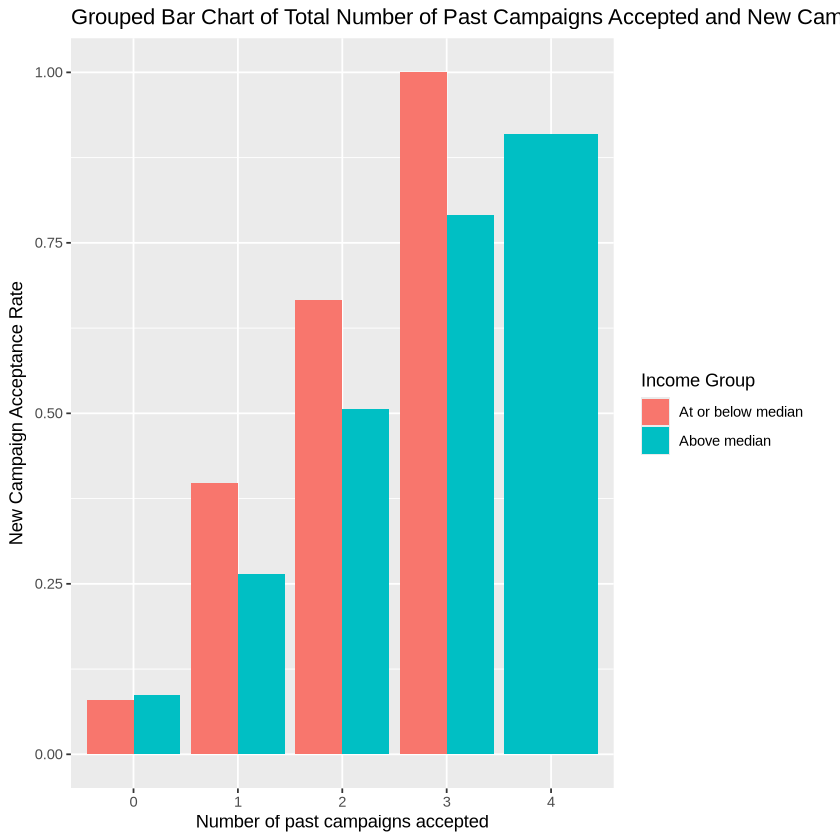

In [8]:
cust_visual <- customers |>
    filter(!is.na(Income)) |>
    mutate(total_number_response = AcceptedCmp1 + AcceptedCmp2 + AcceptedCmp3 + AcceptedCmp4 + AcceptedCmp5,
           high_income = Income > median(Income, na.rm = TRUE)) |>
    group_by(total_number_response, high_income) |>
    summarize(response_rate = mean(Response), .groups = "drop") |>
    ggplot(aes(x = factor(total_number_response), y = response_rate, fill = high_income)) +
     geom_col(position = "dodge") +
    ggtitle("Grouped Bar Chart of Total Number of Past Campaigns Accepted and New Campaign Accept Rate") +
    xlab("Number of past campaigns accepted") +
    ylab("New Campaign Acceptance Rate") +
    labs(fill = "Income Group") +
    scale_fill_discrete(labels = c("At or below median", "Above median")) 
   
cust_visual
    

I begin by taking the customers dataset and filtering out the `Income` values that are empty. This is important because I do not want to include customers that have missing income values in my visual. It will mess with the median calculation.

I then mutate the dataset to create two new variables: `total_number_response` and `high_income`. `total_number_response` is a variable that tells us the total number of times a customer accepted an offer from a previous campaign while `high-income` tells us whether or not the income the customers is above or below the median income in this dataset.

I then `group_by` both `total_number_response` and `high_income`, as I want to show the relationship between these variables and the acceptance rate of the latest campaign. 

Among my group dataset, I calculate the proportion of customers that responded to the latest campaign using `summarize`, creating the new variable `response_rate`. I then drop the groupings.

Creating my visualization, I place `total_number_response` as in my x-axis of `ggplot`. It's important that I ensure the `total_number_response` variable is a factor, so that `ggplot` treats the variable as categorical data, not continuous. 

`response_rate` naturally goes into my y-axis as my response variable and I fill the colour of the bars with the `high_income` variable. 

Setting `geom_col` position to "dodge" makes sure the bars are side-by-side, not stacked, for easy comparison.

`ggtitle`, `xlab`, `ylab`, `labs`, and `scale_fill_discrete` help label the plot title, x-axis heading, y-axis heading, and legend respectively to help readings interpret the visualization.

Interpreting this visualization, I can see that the total number of past responses to previous campaigns is positively associated with the acceptance rate of the next campaign. 

This makes sense, as it seems logical that customers that repeatedly respond to previous campaigns would be likely to respond to the next one. 

A couple of interesting observations: 

1. Customers that have incomes under the median of the dataset actually have higher acceptance rates across almost all of the "Number of past campaigns accepted groups". More research needs to be conducted to determine whether this is due to noise or due to legitimate plausible reason.
2. The "Number of past campaigns accepted groups" = 4 group only has customers with incomes over the median.
3. There is no "Number of past campaigns accepted groups" = 5 group, meaning that within our dataset, there is not customer that responded to all 5 previous campaigns.

## Section 4: Methods and Plan (30 pts)

#### a) Reviewed Question

Let's review the question in focus discussed during assignment 1: What is the probability that a given customer will accept the offer in the next campaign and what are the factors that contribute the most to final accept/reject decision? 

I want to keep this question as the main focus of this assignment. The question is very practical in a real world context as it offers predictive value (probability customer accepts the offer of the next marketing campaign) and inference value (understanding the factors that lead to why a customer may end up accepting/declining a marketing campaign offer).

#### b) Propose one method to address your question of interest using the assigned dataset. Explain why the method is appropriate and why it was chosen (Reasoning: 15 pts)

I propose to use logistic regression as my response variable is a binary event (either accept or reject the next marketing campaign's offer). Logistic regression can help predict the probability of whether the customer accepts or rejects the offer.

I can use the `glm` function to fit a logistic regression model with the acceptance/rejection of the next campaign's offer as the response variable. The covariates will include all other variables, excluding the `ID`, `Dt_Customer`, and the two constant z columns.

However, not all variables in the dataset are required to create a strong and effective model. Thus, I can use the `stepAIC` function to perform stepwise variable selection to choose the best covariates for my model. I am deliberately choosing `stepAIC` over `LASSO` for a few important reasons:
- `stepAIC` only selects variables and fits ordinary coefficients. Odds ratios for inference are easier to interpret whereas `LASSO` shrinks coefficients.
- stepAIC moves factor covariates as one whole group whereas `LASSO` can drop a single dummy level

In my `stepAIC` function, I will use the BIC criterion to raise the penalty incurred when including extra covariates in my model and set the direction argument to `both`.

I will also split my dataset into training and testing datasets. Selection and fitting is only done on the training dataset. The model's performance will be evaluated on the unseen testing dataset, so we can reason how it could perform in a real world context.

After fitting my model, I will also use the `glance` and `anova` functions to test that my fitted model is significantly better than a null model with just the intercept.



#### c) Assumptions and Limitations (Reasoning: 10 pts)

Let's start off by listing the assumptions of my chosen model and methods:
- The response variable is known to be a Bernoulli outcome (you can either accept or reject the next marketing campaign's offer), however I have to assume that the predictor variables I include have to have a linear relationship with the log-odds of the response variable.
- I assume that each customer's acceptance of a marketing campaign offer is independent from one another. One customer's decision does not affect another's.
- I assume that there is no severe collinearity among my covariates. 
- The dataset is observational. Customers were not randomly assigned to campaigns. Customer behaviour is unprompted and natural.
- I assume that there is no data separation. No covariate perfectly separates accepters from rejecters.

Next, these are the limitations of my model and methods:
- The dataset is observational. I cannot conclude any causal effects, only associations.
- The dataset is only from one company, from one time period. The model is limited as the same associative effect may not carry over to future campaigns or other companies.
- The response variable is imbalanced, with only around a 15% acceptance rate. Predicted probabilities will be mostly low.
- The test set will be relatively small after training/testing split. Evaluation can be noisy.
  
  

## Section 5: Computational Code and Output (50 pts)

#### a) Write reproducible code using R to implement the method proposed in part (1). Add comments as needed in your code. (Code: 15pts)

I start by prepping the dataset before the training/testing split and before fitting the logistic regression model.

I first decide to drop the rows with missing income values to make the later training/testing split more clean. I do this by using `drop_na()` on the customers dataframe because only the `Income` column has missing values.

In [9]:
customers_dropped <- customers |>
    drop_na()

customers_dropped

ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,⋯,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
<int>,<int>,<chr>,<chr>,<int>,<int>,<int>,<chr>,<int>,<int>,⋯,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
5524,1957,Graduation,Single,58138,0,0,04-09-2012,58,635,⋯,7,0,0,0,0,0,0,3,11,1
2174,1954,Graduation,Single,46344,1,1,08-03-2014,38,11,⋯,5,0,0,0,0,0,0,3,11,0
4141,1965,Graduation,Together,71613,0,0,21-08-2013,26,426,⋯,4,0,0,0,0,0,0,3,11,0
6182,1984,Graduation,Together,26646,1,0,10-02-2014,26,11,⋯,6,0,0,0,0,0,0,3,11,0
5324,1981,PhD,Married,58293,1,0,19-01-2014,94,173,⋯,5,0,0,0,0,0,0,3,11,0
7446,1967,Master,Together,62513,0,1,09-09-2013,16,520,⋯,6,0,0,0,0,0,0,3,11,0
965,1971,Graduation,Divorced,55635,0,1,13-11-2012,34,235,⋯,6,0,0,0,0,0,0,3,11,0
6177,1985,PhD,Married,33454,1,0,08-05-2013,32,76,⋯,8,0,0,0,0,0,0,3,11,0
4855,1974,PhD,Together,30351,1,0,06-06-2013,19,14,⋯,9,0,0,0,0,0,0,3,11,1


After dropping the missing income values, I will create a new column with the income divided by 10,000. An odds ratio per 1 dollar of income is hard to interpret, whereas an effect on the odds ratio per 10,000 dollars of income is easier and more practical to interpret.

I will do the same thing for product specific spending categories, creating new columns with amount spent divided by 100 instead. 

In [10]:
customers_model <- customers_dropped |>
    mutate(Income_10k = Income / 10000,
    MntWines_100 = MntWines / 100,
    MntFruits_100 = MntFruits / 100,
    MntMeatProducts_100 = MntMeatProducts / 100,
    MntFishProducts_100 = MntFishProducts / 100,
    MntSweetProducts_100 = MntSweetProducts / 100,
    MntGoldProds_100 = MntGoldProds / 100)

customers_model

ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,⋯,Z_CostContact,Z_Revenue,Response,Income_10k,MntWines_100,MntFruits_100,MntMeatProducts_100,MntFishProducts_100,MntSweetProducts_100,MntGoldProds_100
<int>,<int>,<chr>,<chr>,<int>,<int>,<int>,<chr>,<int>,<int>,⋯,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
5524,1957,Graduation,Single,58138,0,0,04-09-2012,58,635,⋯,3,11,1,5.8138,6.35,0.88,5.46,1.72,0.88,0.88
2174,1954,Graduation,Single,46344,1,1,08-03-2014,38,11,⋯,3,11,0,4.6344,0.11,0.01,0.06,0.02,0.01,0.06
4141,1965,Graduation,Together,71613,0,0,21-08-2013,26,426,⋯,3,11,0,7.1613,4.26,0.49,1.27,1.11,0.21,0.42
6182,1984,Graduation,Together,26646,1,0,10-02-2014,26,11,⋯,3,11,0,2.6646,0.11,0.04,0.20,0.10,0.03,0.05
5324,1981,PhD,Married,58293,1,0,19-01-2014,94,173,⋯,3,11,0,5.8293,1.73,0.43,1.18,0.46,0.27,0.15
7446,1967,Master,Together,62513,0,1,09-09-2013,16,520,⋯,3,11,0,6.2513,5.20,0.42,0.98,0.00,0.42,0.14
965,1971,Graduation,Divorced,55635,0,1,13-11-2012,34,235,⋯,3,11,0,5.5635,2.35,0.65,1.64,0.50,0.49,0.27
6177,1985,PhD,Married,33454,1,0,08-05-2013,32,76,⋯,3,11,0,3.3454,0.76,0.10,0.56,0.03,0.01,0.23
4855,1974,PhD,Together,30351,1,0,06-06-2013,19,14,⋯,3,11,1,3.0351,0.14,0.00,0.24,0.03,0.03,0.02


After dividing the `Income` and `Mnt` columns by 10,000 and 100 respectively. The last prep step I complete is collapsing the rare marital levels into one grouping. Three marital statuses: Absurd, YOLO, and Alone are frankly not legitimate marital statuses and grouping them into one alternative `Other` label gives us one noisy coefficient instead of three seperate ones.

I can `mutate` the marital status column by using `if_else` and `%in%` which evaluates to true when the value in `Marital_Status` is one of `Absurd`, `YOLO`, or `Alone`. 

In [11]:
customers_model_ready <- customers_model |>
    mutate(Marital_Status = if_else(
        Marital_Status %in% c("Absurd", "YOLO", "Alone"),
        "Other",
        Marital_Status))

customers_model_ready
count(customers_model_ready, Marital_Status)

ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,⋯,Z_CostContact,Z_Revenue,Response,Income_10k,MntWines_100,MntFruits_100,MntMeatProducts_100,MntFishProducts_100,MntSweetProducts_100,MntGoldProds_100
<int>,<int>,<chr>,<chr>,<int>,<int>,<int>,<chr>,<int>,<int>,⋯,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
5524,1957,Graduation,Single,58138,0,0,04-09-2012,58,635,⋯,3,11,1,5.8138,6.35,0.88,5.46,1.72,0.88,0.88
2174,1954,Graduation,Single,46344,1,1,08-03-2014,38,11,⋯,3,11,0,4.6344,0.11,0.01,0.06,0.02,0.01,0.06
4141,1965,Graduation,Together,71613,0,0,21-08-2013,26,426,⋯,3,11,0,7.1613,4.26,0.49,1.27,1.11,0.21,0.42
6182,1984,Graduation,Together,26646,1,0,10-02-2014,26,11,⋯,3,11,0,2.6646,0.11,0.04,0.20,0.10,0.03,0.05
5324,1981,PhD,Married,58293,1,0,19-01-2014,94,173,⋯,3,11,0,5.8293,1.73,0.43,1.18,0.46,0.27,0.15
7446,1967,Master,Together,62513,0,1,09-09-2013,16,520,⋯,3,11,0,6.2513,5.20,0.42,0.98,0.00,0.42,0.14
965,1971,Graduation,Divorced,55635,0,1,13-11-2012,34,235,⋯,3,11,0,5.5635,2.35,0.65,1.64,0.50,0.49,0.27
6177,1985,PhD,Married,33454,1,0,08-05-2013,32,76,⋯,3,11,0,3.3454,0.76,0.10,0.56,0.03,0.01,0.23
4855,1974,PhD,Together,30351,1,0,06-06-2013,19,14,⋯,3,11,1,3.0351,0.14,0.00,0.24,0.03,0.03,0.02


Marital_Status,n
<chr>,<int>
Divorced,232
Married,857
Other,7
Single,471
Together,573
Widow,76


With prepping the dataset out of the way, I can now start by splitting the prepped dataset into a training and testing dataset. 

I make sure to set a seed to ensure that my work is reproducible. I also stratify by datasets by `Response` to make sure that both the training and testing dataset has the same proportion of campaign accepters/rejecters.

In [12]:
set.seed(777) # Let's get lucky!

split <- initial_split(customers_model_ready, prop = 0.7, strata = Response)
training_set <- training(split)
testing_set <- testing(split)
count(training_set, Response)
count(testing_set, Response)

Response,n
<int>,<int>
0,1318
1,233


Response,n
<int>,<int>
0,565
1,100


After splitting the data, I fit the `glm` logistic regression model using all the variables, making sure to use the `Income_10k` column and `Mnt_100` columns instead of their undivided counterparts.

I set `family` to binomial for logistic regression and data to be my training dataset.\

This is a bit tedious.

In addition, I also fit a null model with just the intercept as a predictor which will come in handy for the `step_AIC` function I call on later.

In [13]:
model_fit <- glm(Response ~ Year_Birth + Education + Marital_Status + Income_10k +
    Kidhome + Teenhome + Recency +
    MntWines_100 + MntFruits_100 + MntMeatProducts_100 + MntFishProducts_100 +
    MntSweetProducts_100 + MntGoldProds_100 +
    NumDealsPurchases + NumWebPurchases + NumCatalogPurchases +
    NumStorePurchases + NumWebVisitsMonth +
    AcceptedCmp1 + AcceptedCmp2 + AcceptedCmp3 + AcceptedCmp4 + AcceptedCmp5 +
    Complain,
  family = binomial, data = training_set)

model_null <- glm(Response ~ 1, family = binomial, data = training_set)

tidy_model_fit <- tidy(model_fit, exponentiated = TRUE)

tidy_model_fit

term,estimate,std.error,statistic,p.value
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
(Intercept),3.290388549,16.856376093,0.1952014,8.452353e-01
Year_Birth,-0.003054749,0.008547467,-0.3573864,7.208025e-01
EducationBasic,-0.653447376,0.850458683,-0.7683470,4.422811e-01
EducationGraduation,0.340149330,0.376815815,0.9026939,3.666884e-01
EducationMaster,0.496728478,0.426605639,1.1643739,2.442725e-01
EducationPhD,1.355836850,0.407944434,3.3235822,8.886924e-04
Marital_StatusMarried,-0.998537507,0.301642694,-3.3103321,9.318532e-04
Marital_StatusOther,0.487336002,0.913303046,0.5335973,5.936202e-01
Marital_StatusSingle,0.228536741,0.303538802,0.7529078,4.515053e-01


Now that the logistic regression model is fitted, I can now run `step_AIC`. 

This means that each variable has to cut the deviance more than if I chose AIC instead in order to be included in the model.

In my scope argument, I set lower to equal a null model while the upper argument is set to my full model.

In my direction argument, I chose to "both" as it allows my model to both drop or add terms retroactively if it improves the models fit.

In my K argument, I chose to set it to k = log(nobs(model_fit)) for BIC.

In [14]:
model_final <- MASS::stepAIC(
    model_fit, 
    scope = list(lower = model_null, upper = model_fit),
    direction = "both",
    k = log(nobs(model_fit)),
    trace = FALSE)

model_final

tidy(model_final, exponentiate = TRUE, conf.int = TRUE)
    


Call:  glm(formula = Response ~ Marital_Status + Teenhome + Recency + 
    MntMeatProducts_100 + NumDealsPurchases + NumWebPurchases + 
    NumStorePurchases + NumWebVisitsMonth + AcceptedCmp1 + AcceptedCmp2 + 
    AcceptedCmp3 + AcceptedCmp4 + AcceptedCmp5, family = binomial, 
    data = training_set)

Coefficients:
           (Intercept)   Marital_StatusMarried     Marital_StatusOther  
              -2.00148                -1.02704                 0.86595  
  Marital_StatusSingle  Marital_StatusTogether     Marital_StatusWidow  
               0.15339                -1.16729                 0.21729  
              Teenhome                 Recency     MntMeatProducts_100  
              -0.99138                -0.02711                 0.25351  
     NumDealsPurchases         NumWebPurchases       NumStorePurchases  
               0.16074                 0.14940                -0.13541  
     NumWebVisitsMonth            AcceptedCmp1            AcceptedCmp2  
               0.17452 

term,estimate,std.error,statistic,p.value,conf.low,conf.high
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
(Intercept),0.1351350,0.477648785,-4.1902775,2.786135e-05,0.05235489,0.3411203
Marital_StatusMarried,0.3580645,0.290151104,-3.5396801,4.006123e-04,0.20363098,0.6370398
Marital_StatusOther,2.3772587,0.871123283,0.9940591,3.201941e-01,0.40092408,14.1130165
Marital_StatusSingle,1.1657772,0.289216321,0.5303572,5.958643e-01,0.66634068,2.0762471
Marital_StatusTogether,0.3112099,0.320833179,-3.6383008,2.744428e-04,0.16551369,0.5843242
Marital_StatusWidow,1.2427090,0.468699712,0.4636096,6.429275e-01,0.48155364,3.0565293
Teenhome,0.3710638,0.216987731,-4.5688355,4.904415e-06,0.24035317,0.5632533
Recency,0.9732553,0.003281572,-8.2609440,1.445249e-16,0.96688428,0.9794179
MntMeatProducts_100,1.2885434,0.047062083,5.3867663,7.173661e-08,1.17623743,1.4152827


Using tidy, I can see some notable observations from my coefficient estimates: 
- Past campaign acceptance all dominate in which an acceptance in a previous campaign drastically increases the odds that the next marketing campaign is also accepted.
- The number of teenagers in the household drastically decreases the odds of accepting the next marketing campaign interestingly.
- Recency has the smallest p value, with each extra day of since the last purchase lower the odds by about 2.7%.

To determine whether the final model we created is significantly better than our null model, I use the `glance` and `anova` functions. 

In [15]:
glance(model_final)
anova(model_null, model_final, test = "Chisq")


null.deviance,df.null,logLik,AIC,BIC,deviance,df.residual,nobs
<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>
1312.457,1550,-437.3901,910.7802,1007.02,874.7802,1533,1551


,Resid. Df,Resid. Dev,Df,Deviance,Pr(>Chi)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,1550,1312.4572,NA,NA,NA
2,1533,874.7802,17,437.677,2.390282e-82


From the output of `glance` and `anova`, I can see that the deviance drops drastically from 1312 for the null model to 874 for the final model.

With the p value far below a 0.05 level of significance, the final model is significantly better. 

#### b) Create *only one* high-quality, creative and informative visualization or table to summarize results.  (Code: 5pts, Viz: 5pts, Reasoning: 5pts)

Doing a bit of research on a high-quality visualization for my work, I came across a ROC curve or a receiver operating characteristic curve. 

The ROC curve is a graph that shows the performance of a binary classification model. However, my fitted logistic regression model outputs the probability that the next marketing campaign's offer is accepted.

We can turn probabilities given by the logistic regression model into classifications using a set threshold. If the probability is above a set threshold, classify the customer as an accepter, if the probability is under the threshold, classify as rejecter.

Well why not use a threshold of 50%? It seems like a natural choice. Any probability over 50% we can classify as an accepter and under 50% we can classify as a rejecter. The problem is that few customers will be predicted a probability over 50% from the logistic regression. Looking from the overall training and testing datasets we can see that only around 15% of customers accepted the latest campaign's offer. 

Another problem is that real-world mistakes have unequal costs. For example, a medical diagnosis logistic regression model can say that a patient only has a 35% chance of a serious disease. It could be life-costing mistake to wait until the model says that the chance is above 50%.

In the case of the marketing campaign dataset, it is way easier to deem a customer as potential accepter and send them the campaign offer anyways as the cost is low compared to missing out on a potential customer. 

Instead of guessing what threshold fits best, we can use a ROC to illustrate the different thresholds and the performance of classification to see how my fitted logistic regression model performs at different thresholds.

The accompanying metric AUC also gives a great way to measure the performance of the model which will be discussed later.

This is a great visual as it has significant real world context usage cases if I were to actually use this logistic regression model as a part of my decision-making process for a company.

Let's begin!

First, I need to predict the probabilities on our testing data so I can compute the acceptance true positive and false positive rates which live on the y-axis and x-axis respectively.

In [16]:
test_with_pred <- testing_set |>
    mutate(pred_prob = predict(model_final, newdata = testing_set, type = "response"))

test_with_pred

ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,⋯,Z_Revenue,Response,Income_10k,MntWines_100,MntFruits_100,MntMeatProducts_100,MntFishProducts_100,MntSweetProducts_100,MntGoldProds_100,pred_prob
<int>,<int>,<chr>,<chr>,<int>,<int>,<int>,<chr>,<int>,<int>,⋯,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
2174,1954,Graduation,Single,46344,1,1,08-03-2014,38,11,⋯,11,0,4.6344,0.11,0.01,0.06,0.02,0.01,0.06,0.058318324
6182,1984,Graduation,Together,26646,1,0,10-02-2014,26,11,⋯,11,0,2.6646,0.11,0.04,0.20,0.10,0.03,0.05,0.063141911
7446,1967,Master,Together,62513,0,1,09-09-2013,16,520,⋯,11,0,6.2513,5.20,0.42,0.98,0.00,0.42,0.14,0.031232949
4855,1974,PhD,Together,30351,1,0,06-06-2013,19,14,⋯,11,1,3.0351,0.14,0.00,0.24,0.03,0.03,0.02,0.152619549
5899,1950,PhD,Together,5648,1,1,13-03-2014,68,28,⋯,11,0,0.5648,0.28,0.00,0.06,0.01,0.01,0.13,0.403553273
2278,1985,2n Cycle,Single,33812,1,0,03-11-2012,86,4,⋯,11,0,3.3812,0.04,0.17,0.19,0.30,0.24,0.39,0.053650135
1993,1949,PhD,Married,58607,0,1,23-12-2012,63,867,⋯,11,0,5.8607,8.67,0.00,0.86,0.00,0.00,0.19,0.030589779
4047,1954,PhD,Married,65324,0,1,11-01-2014,0,384,⋯,11,0,6.5324,3.84,0.00,1.02,0.21,0.32,0.05,0.051990235
7892,1969,Graduation,Single,18589,0,0,02-01-2013,89,6,⋯,11,0,1.8589,0.06,0.04,0.25,0.15,0.12,0.13,0.059427814


Now with probability predictions added to `testing_set`, I can now work on creating the thresholds and calculating the true positive rate, false positive rate, and auc.

The true positive rate asks: of the customers who actually accepted a campaign offer, how many did the model catch? For example, if 80 out of 100 real accepters are flagged at the threshold of 0.5, the `tpr` is 0.8.  

The false positive rate is the same. It asks: of customers who really rejected the campaign, how many did the logistic regression model wrongly flag as accepters?

The AUC (area under curve) is a number that represents the probability that the logistic regression model gave a higher predicted probability to a random accepter versus a random rejecter given the pair. 

Looking online, the pROC library offers useful functions that I can use to directly calculate these rates as well as way to plot the ROC curve using `ggroc`. Importing the library at the top of this notebook, I use these functions to make my life easier.

Setting levels: control = 0, case = 1

Setting direction: controls < cases



Area under the curve: 0.8703

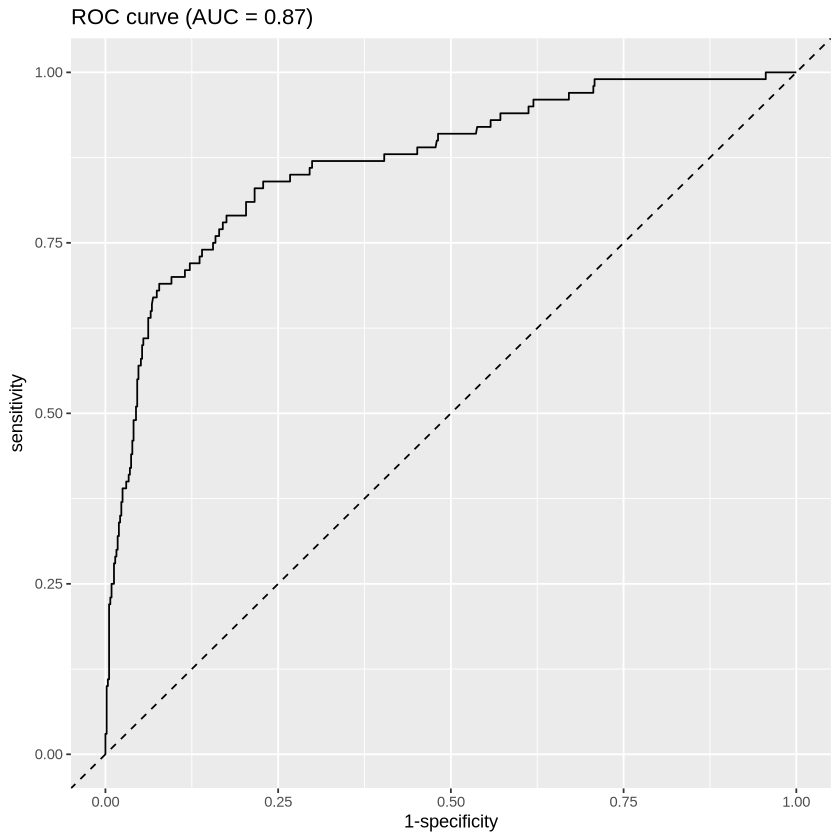

In [17]:
roc_obj <- roc(test_with_pred$Response, test_with_pred$pred_prob)
auc(roc_obj)
ggroc(roc_obj, legacy.axes = TRUE) +
  geom_abline(slope = 1, intercept = 0, linetype = "dashed") +
  labs(title = paste0("ROC curve (AUC = ", round(auc(roc_obj), 3), ")"))


I also want to see the threshold that maximises the difference between the true positive rate and the false positive rate. I can do that with another imported function from the pROC library.

In [18]:
coords(roc_obj, "best", ret = c("threshold", "sensitivity", "specificity"))

threshold,sensitivity,specificity
<dbl>,<dbl>,<dbl>
0.1718462,0.79,0.8247788


If we value a correctly identified accepter as much as a falsely identified accepter, we can see that the optimal classification threshold is around 17%.

This means in real world practice when identifying customers to target for our next marketing campaign, customers that are predicted a probability higher than 17% should be classified as an offer accepter and customers predicted lower than 17% should be classified as an offer rejecter.

#### c) In 3 or 4 sentences give a brief interpretation of the results. If needed, comment on any unexpected result or potential problems with the analysis, and possible ways to address issues encountered. If results are as expected, explain how they address the question of interest. **Do not exceed the 4 sentences limit** (Reasoning: 15pts).

Overall Analysis Takeaways: 

1. The AUC is 0.87 and this is a good metric for the logistic regression model, with an 87% probability that the model predicts a higher probability for an actual accepter versus a rejecter.
2. The strongest factors affecting campaign acceptance odds were past campaign acceptance (increase odds), `Teenhome` (decrease odds), and `Recency` (decrease odds).
3. While the probability of a given customer accepting the next marketing campaign's offer varies by customer characteristics, setting a threshold of 17% to classify accepters/rejecters maximises the difference between the true positive rate and false positive rate.
4. The results of this analysis answer my question of interest by giving usable offer acceptance probabilities, naming the strongest factors associated with the acceptance/rejection decision, and giving a threshold that can be used for real-world customer targeting.

## Section 6: Use of AI tools (Mechanics 5pts)

AI tools (chatbots) were used to debug code and to gain feedback on wording. I understand and I am able to explain all parts of the assignment submission.